# Đánh giá PCAP-Combined-Refit

Nạp model đã fit và chấm lại test theo hai nguồn cùng test gộp. Đổi `run` và `prepared` nếu muốn đọc một lượt mới. Test gộp nối các dòng dự đoán từ cả hai nguồn trước khi tính chỉ số.

In [1]:
from datetime import datetime
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "configs/pcap_sessions_20261112.json").is_file())
sys.path.insert(0, str(root / "src"))
prepared = root / "experiments/pcap-scapy-20261112-seed42"
original = root / "experiments/pcap-combined-refit-seed42"

from hashlib import file_digest
from io import BytesIO
from IPython.display import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from check_model import check_model, load_model
from dataset import SOURCES, numeric_features
from train import MODEL_ID

run = original
card = json.loads((run / "REFIT_CARD.json").read_text(encoding="utf-8"))
model_path = run / f"{MODEL_ID}.joblib"
with model_path.open("rb") as stream:
    assert file_digest(stream, "sha256").hexdigest() == card["model_sha256"]
artifact = load_model(model_path)
classes = np.asarray(artifact["classes"])

## 1. Kiểm tra trên holdout

Accuracy đếm tỷ lệ đúng toàn bộ. Macro-F1 lấy trung bình F1 của bốn lớp với trọng số ngang nhau để nhìn rõ lớp ít mẫu. FPR đo phần flow BENIGN bị cảnh báo. Recall ATTACK tính tỷ lệ tấn công được phát hiện sau khi gộp ba lớp tấn công. Cell dùng `Label` từ split làm ground truth và kiểm tra các chỉ số khớp với model card.

In [2]:
scored = {}
for source in SOURCES:
    frame = pd.read_csv(prepared / "splits" / source / "test.csv")
    pred = classes[artifact["model"].predict(numeric_features(frame))]
    scored[source] = pd.DataFrame({"truth": frame.Label, "prediction": pred})
scored["combined"] = pd.concat(scored.values(), ignore_index=True)

rows = {}
for source, result in scored.items():
    normal = result.truth.eq("BENIGN")
    metrics = {"accuracy": accuracy_score(result.truth, result.prediction),
               "macro_f1": f1_score(result.truth, result.prediction, labels=classes,
                                    average="macro", zero_division=0),
               "benign_false_positive_rate": result.prediction[normal].ne("BENIGN").mean(),
               "attack_recall": result.prediction[~normal].ne("BENIGN").mean()}
    for name, value in metrics.items():
        assert np.isclose(value, card["reference_metrics"][source][name])
    rows[source] = {"Flows": len(result), **{name: round(value * 100, 2) for name, value in metrics.items()}}
display(pd.DataFrame.from_dict(rows, orient="index").rename(columns={
    "accuracy": "Accuracy (%)", "macro_f1": "Macro-F1 (%)",
    "benign_false_positive_rate": "FPR BENIGN (%)", "attack_recall": "Recall ATTACK (%)"}))

,Flows,Accuracy (%),Macro-F1 (%),FPR BENIGN (%),Recall ATTACK (%)
cicids2017,16035,93.73,69.59,3.13,92.73
insdn,10440,99.30,83.50,0.16,99.56
combined,26475,95.92,86.04,1.95,95.42


## 2. Đọc lỗi từng lớp

Ma trận dùng hàng là nhãn thật, cột là dự đoán. Với BRUTE_FORCE, đọc precision và recall cùng support để thấy vừa có ca phát hiện đúng vừa có cảnh báo nhầm. Dòng DOS và cột BENIGN cho biết bao nhiêu flow DOS bị bỏ sót.

,precision,recall,f1-score,support
BENIGN,0.9208,0.9805,0.9497,9323.0
BRUTE_FORCE,0.3850,0.9290,0.5444,155.0
DOS,0.9968,0.9224,0.9582,9886.0
RECON,0.9952,0.9833,0.9892,7111.0


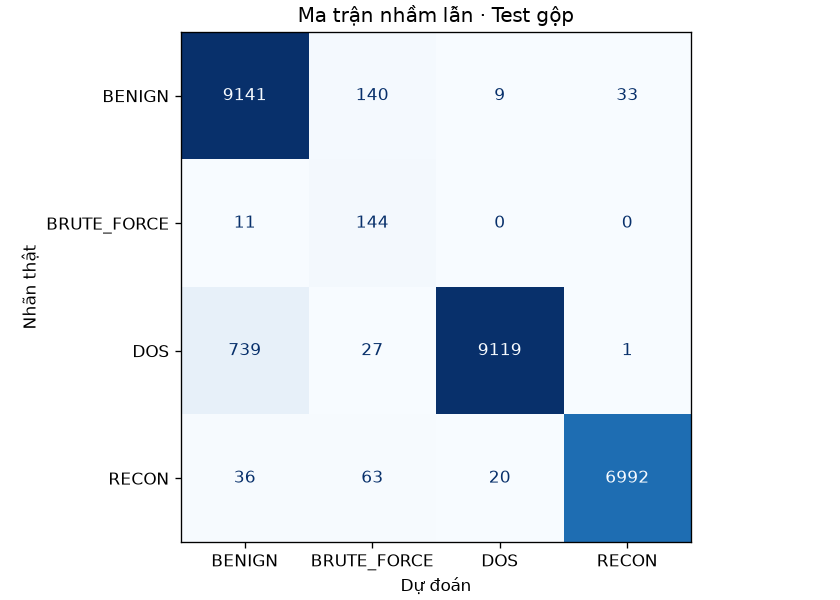

In [3]:
combined = scored["combined"]
report = classification_report(combined.truth, combined.prediction, labels=classes,
                               output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.loc[classes].round(4))
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ConfusionMatrixDisplay.from_predictions(combined.truth, combined.prediction, labels=classes,
                                         cmap="Blues", colorbar=False, ax=ax)
ax.set(xlabel="Dự đoán", ylabel="Nhãn thật", title="Ma trận nhầm lẫn · Test gộp")
with BytesIO() as image:
    fig.savefig(image, format="png", dpi=120)
    display(Image(data=image.getvalue()))
plt.close(fig)

## 3. So với từng mô hình tầng 1

Dùng chính ba base learner đã fit trong artifact để dự đoán trên cùng test gộp. Cả ba học từ cùng 20.307 flow, nên phép so sánh đo mức cải thiện của Stacking so với từng base learner trong cấu hình cuối.

In [4]:
x_test = pd.concat([numeric_features(pd.read_csv(prepared / "splits" / source / "test.csv"))
                    for source in SOURCES], ignore_index=True)
stack = artifact["model"]
models = {**stack.named_estimators_, "stacking": stack}
comparison = {}
for name, model in models.items():
    predicted = classes[model.predict(x_test)]
    comparison[name] = {
        "Accuracy (%)": 100 * accuracy_score(combined.truth, predicted),
        "Macro-F1 (%)": 100 * f1_score(combined.truth, predicted, labels=classes, average="macro"),
    }
display(pd.DataFrame.from_dict(comparison, orient="index").round(2))

,Accuracy (%),Macro-F1 (%)
rf,64.54,45.05
xgb,95.59,72.18
lgbm,95.44,72.05
stacking,95.92,86.04


## 4. Smoke test sau khi nạp model

Smoke test so dự đoán trên một CSV nhỏ với `ExpectedPrediction` của artifact. Độ khớp 100% cho biết môi trường nạp model tái lập đúng dự đoán mẫu. Dùng mục holdout để đọc Accuracy và [hướng dẫn Windows](../docs/WINDOWS_LIVE.md) để thử capture mới.

In [5]:
for source in SOURCES:
    print(source)
    check_model(model_path, run / source / "smoke.csv")

cicids2017
Prediction match: 100.00%
insdn
Prediction match: 100.00%
